# Notebook 05: Comparison with Sánchez Zaballa (2025)

**Object:** MG3 J163554+3629 (z = 3.648)
**Depends on:** UltraNest samples from notebook 02 (`ultranest_samples_1zone.npy`)

**What this notebook does:**
1. Full parameter table — our results vs Sánchez Zaballa (2025)
2. Eddington ratio posterior vs their value
3. M_BH posterior overlaid with published values
4. Seed black hole mass constraint across spin values
5. M_BH posteriors across the η (BH spin) grid

**Outputs saved to `../../results/plots/`:**
- `comparison_posteriors.png`
- `comparison_lambda_edd.png`
- `comparison_seed_mass.png`
- `comparison_mbh_all_eta.png`

In [3]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import matplotlib.pyplot as plt
import corner
import os
from scipy.optimize import brentq
%matplotlib inline

os.makedirs('../../results/plots', exist_ok=True)

# ============================================================
# LOAD ULTRANEST SAMPLES FROM NOTEBOOK 02
# ============================================================
samples     = np.load('../results/models/ultranest_samples_1zone.npy')
results_un  = np.load('../results/models/ultranest_results_1zone.npy', allow_pickle=True).item()

# Free params used in notebook 02 UltraNest
# UPDATE these if you used different free params in notebook 02
free_params = ['B', 'M_BH', 'accr_eff']   # 3-param run
# free_params = ['B', 'BulkFactor', 'N', 'M_BH', 'L_Disk', 'T_DT']  # 6-param run

print(f'Loaded {len(samples)} posterior samples.')
print(f'Free parameters: {free_params}')
print(f'log Z (this work) = {results_un["logz"]:.3f} +/- {results_un["logzerr"]:.3f}')

Loaded 5135 posterior samples.
Free parameters: ['B', 'M_BH', 'accr_eff']
log Z (this work) = -20.656 +/- 0.230


---
## 1. Full parameter table comparison
Our posterior medians and 1σ intervals vs Sánchez Zaballa (2025).

In [4]:
# ============================================================
# SANCHEZ ZABALLA (2025) PUBLISHED VALUES
# Update these if you have more precise values from the paper
# ============================================================
jose = {
    'M_BH (M_sun)'  : 1.10e9,
    'L_Disk (erg/s)': 1.38e46,
    'B (G)'         : 0.05,
    'BulkFactor'    : 15.0,
    'p'             : 1.59,
    'p_1'           : 3.07,
    'gamma_break'   : 400.0,
    'accr_eff'      : 0.09,
    'theta (deg)'   : 3.0,
    'z'             : 3.648,
}

# Posterior medians and 1 sigma
post_med = np.median(samples, axis=0)
post_lo  = np.percentile(samples, 16, axis=0)
post_hi  = np.percentile(samples, 84, axis=0)

print(f"{'Parameter':<20} {'This work (median)':<25} {'1sigma range':<30} {'Sanchez Zaballa 2025':<22}")
print('-' * 97)

for i, name in enumerate(free_params):
    med = post_med[i]
    lo  = post_lo[i]
    hi  = post_hi[i]
    # Match to jose table
    jose_key = {'B': 'B (G)', 'M_BH': 'M_BH (M_sun)',
                'accr_eff': 'accr_eff', 'L_Disk': 'L_Disk (erg/s)',
                'BulkFactor': 'BulkFactor'}.get(name, name)
    jose_val = jose.get(jose_key)
    jose_str = f'{jose_val:.4e}' if jose_val is not None else 'N/A'
    print(f"{name:<20} {med:<25.4e} [{lo:.4e}, {hi:.4e}]          {jose_str}")

print('\n--- Fixed parameters (frozen in our UltraNest run) ---')
fixed = [
    ('p',          1.590, jose['p']),
    ('p_1',        2.966, jose['p_1']),
    ('gamma_break',381.0, jose['gamma_break']),
    ('theta (deg)',3.0,   jose['theta (deg)']),
    ('z',          3.648, jose['z']),
]
for label, our_val, jose_val in fixed:
    print(f'  {label:<20}: ours = {our_val:.4f}   Jose = {jose_val:.4f}')

Parameter            This work (median)        1sigma range                   Sanchez Zaballa 2025  
-------------------------------------------------------------------------------------------------
B                    6.1342e-02                [5.7016e-02, 6.5347e-02]          5.0000e-02
M_BH                 2.0675e+09                [1.7111e+09, 2.4197e+09]          1.1000e+09
accr_eff             7.9673e-02                [7.2443e-02, 8.8668e-02]          9.0000e-02

--- Fixed parameters (frozen in our UltraNest run) ---
  p                   : ours = 1.5900   Jose = 1.5900
  p_1                 : ours = 2.9660   Jose = 3.0700
  gamma_break         : ours = 381.0000   Jose = 400.0000
  theta (deg)         : ours = 3.0000   Jose = 3.0000
  z                   : ours = 3.6480   Jose = 3.6480


---
## 2. Eddington ratio comparison

In [9]:
# ============================================================
# COMPUTE EDDINGTON RATIO FROM POSTERIOR
# ============================================================
mbh_idx = free_params.index('M_BH')
M_BH_s  = samples[:, mbh_idx]
L_Edd_s = 1.26e38 * M_BH_s

# If L_Disk is a free parameter use its posterior,
# otherwise use the fixed best-fit value
if 'L_Disk' in free_params:
    ldisk_idx = free_params.index('L_Disk')
    L_disk_s  = samples[:, ldisk_idx]
else:
    L_disk_s  = np.full(len(M_BH_s), 1.726e46)  # fixed best-fit from Minuit

lambda_s = L_disk_s / L_Edd_s

med_lam = np.median(lambda_s)
lo_lam  = np.percentile(lambda_s, 16)
hi_lam  = np.percentile(lambda_s, 84)

# Jose values
MBH_jose    = 1.1e9
Ldisk_jose  = 1.38e46
lambda_jose = Ldisk_jose / (1.26e38 * MBH_jose)

print('=== Eddington ratio comparison ===')
print(f'This work:          lambda_Edd = {med_lam:.4f}  +{hi_lam-med_lam:.4f}  -{med_lam-lo_lam:.4f}')
print(f'Sanchez Zaballa:    lambda_Edd = {lambda_jose:.4f}')
direction = 'higher' if lambda_jose > med_lam else 'lower'
print(f'Difference: {(lambda_jose-med_lam)/lambda_jose*100:.1f}% {direction} than Jose')

print('\n=== Black hole mass comparison ===')
med_mbh = np.median(M_BH_s)
lo_mbh  = np.percentile(M_BH_s, 16)
hi_mbh  = np.percentile(M_BH_s, 84)
print(f'This work:          M_BH = {med_mbh:.3e}  +{hi_mbh-med_mbh:.3e}  -{med_mbh-lo_mbh:.3e} M_sun')
print(f'Sanchez Zaballa:    M_BH = {MBH_jose:.3e} M_sun')

=== Eddington ratio comparison ===
This work:          lambda_Edd = 0.0663  +0.0138  -0.0096
Sanchez Zaballa:    lambda_Edd = 0.0996
Difference: 33.5% higher than Jose

=== Black hole mass comparison ===
This work:          M_BH = 2.067e+09  +3.522e+08  -3.564e+08 M_sun
Sanchez Zaballa:    M_BH = 1.100e+09 M_sun


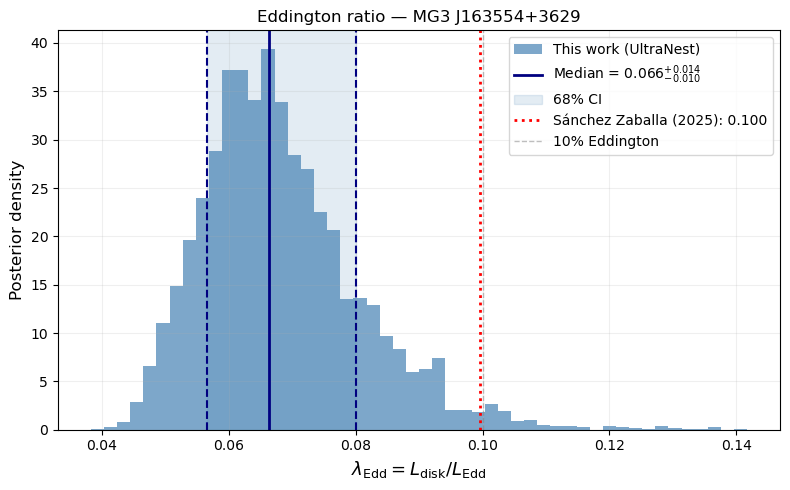

Saved: comparison_lambda_edd.png


In [10]:
# Eddington ratio plot
fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(lambda_s, bins=50, color='steelblue', alpha=0.7,
        density=True, label='This work (UltraNest)')
ax.axvline(med_lam, color='navy', lw=2,
           label=fr'Median = {med_lam:.3f}$^{{+{hi_lam-med_lam:.3f}}}_{{-{med_lam-lo_lam:.3f}}}$')
ax.axvline(lo_lam, color='navy', lw=1.5, ls='--')
ax.axvline(hi_lam, color='navy', lw=1.5, ls='--')
ax.axvspan(lo_lam, hi_lam, alpha=0.15, color='steelblue', label='68% CI')
ax.axvline(lambda_jose, color='red', lw=2, ls=':',
           label=f'Sánchez Zaballa (2025): {lambda_jose:.3f}')
ax.axvline(0.10, color='gray', lw=1, ls='--', alpha=0.5,
           label='10% Eddington')

ax.set_xlabel(r'$\lambda_{\rm Edd} = L_{\rm disk}/L_{\rm Edd}$', fontsize=13)
ax.set_ylabel('Posterior density', fontsize=12)
ax.set_title('Eddington ratio — MG3 J163554+3629', fontsize=12)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.savefig('../../results/plots/comparison_lambda_edd.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: comparison_lambda_edd.png')

---
## 3. Posterior plots overlaid with José's values

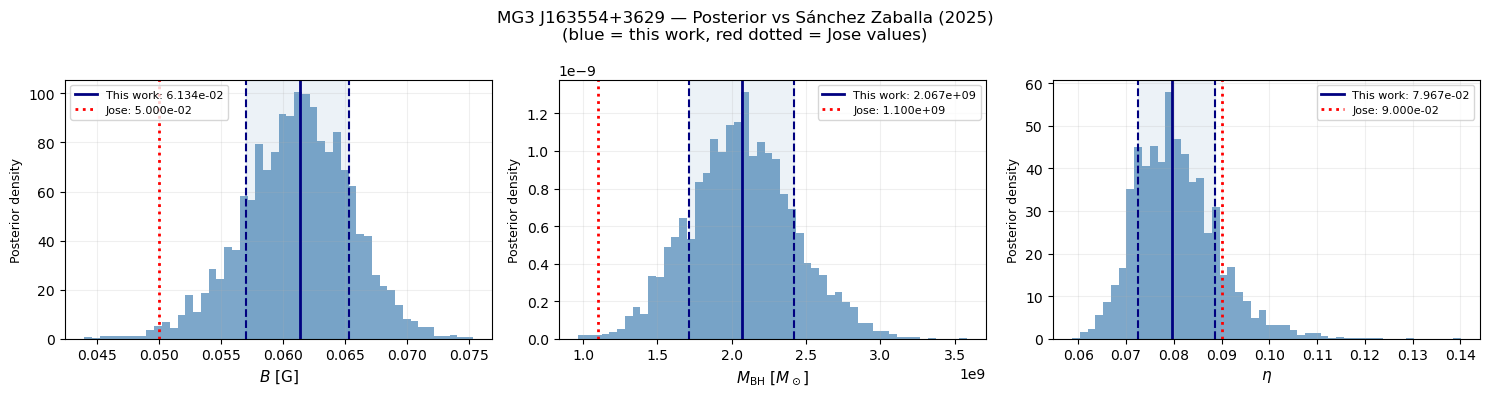

Saved: comparison_posteriors.png


In [11]:
latex_labels = {
    'B':          r'$B$ [G]',
    'M_BH':       r'$M_{\rm BH}$ [$M_\odot$]',
    'accr_eff':   r'$\eta$',
    'BulkFactor': r'$\Gamma$',
    'N':          r'$N$ [cm$^{-3}$]',
    'L_Disk':     r'$L_{\rm disk}$ [erg s$^{-1}$]',
    'T_DT':       r'$T_{\rm DT}$ [K]',
}
jose_point = {
    'B':          0.05,
    'M_BH':       1.1e9,
    'accr_eff':   0.09,
    'BulkFactor': 15.0,
    'L_Disk':     1.38e46,
    'N':          None,
    'T_DT':       None,
}

ncols = min(len(free_params), 3)
nrows = (len(free_params) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(5*ncols, 4*nrows))
axes = np.array(axes).flatten()

for i, (name, ax) in enumerate(zip(free_params, axes)):
    s   = samples[:, i]
    med = np.median(s)
    lo  = np.percentile(s, 16)
    hi  = np.percentile(s, 84)

    ax.hist(s, bins=50, color='steelblue', alpha=0.7, density=True)
    ax.axvline(med, color='navy', lw=2,   label=f'This work: {med:.3e}')
    ax.axvline(lo,  color='navy', lw=1.5, ls='--')
    ax.axvline(hi,  color='navy', lw=1.5, ls='--')
    ax.axvspan(lo, hi, alpha=0.1, color='steelblue')

    jose_v = jose_point.get(name)
    if jose_v is not None:
        ax.axvline(jose_v, color='red', lw=2, ls=':',
                   label=f'Jose: {jose_v:.3e}')

    ax.set_xlabel(latex_labels.get(name, name), fontsize=11)
    ax.set_ylabel('Posterior density', fontsize=9)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.2)

# Hide unused axes
for ax in axes[len(free_params):]:
    ax.set_visible(False)

plt.suptitle('MG3 J163554+3629 — Posterior vs Sánchez Zaballa (2025)\n'
             '(blue = this work, red dotted = Jose values)',
             fontsize=12)
plt.tight_layout()
plt.savefig('../../results/plots/comparison_posteriors.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: comparison_posteriors.png')

---
## 4. Seed black hole mass constraint

How massive must the BH seed be to grow to M_BH by z=3.65 (t=1.72 Gyr after z=20)?

Growth equation: M_seed = M_BH × exp(−λ × t_avail / t_Salp)

where t_Salp(η) = 0.45 × (η/0.1) Gyr

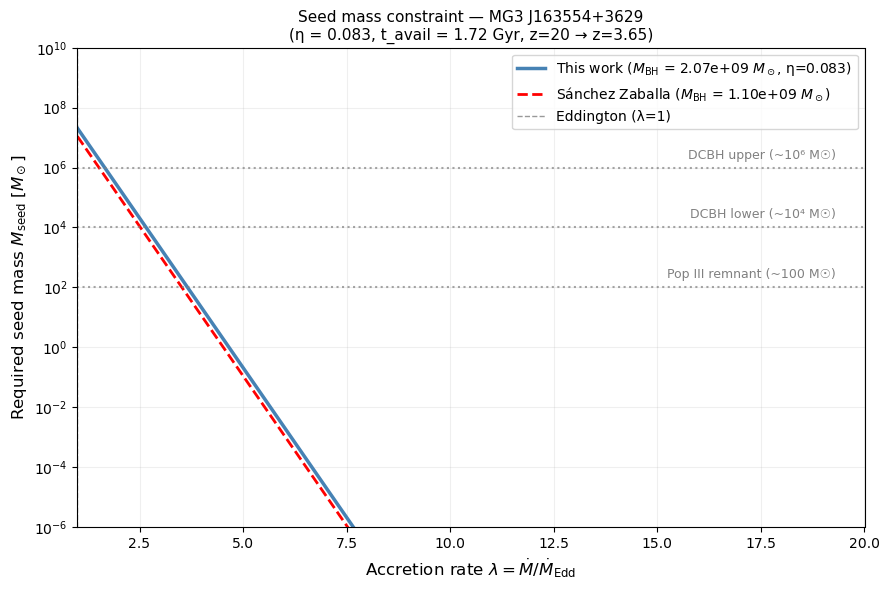

=== Seed mass at Eddington accretion (λ=1) ===
This work:          M_seed = 2.068e+07 M_sun
Sanchez Zaballa:    M_seed = 1.100e+07 M_sun

=== Minimum λ for DCBH seed (10⁶ M_sun) ===
This work:          lambda_min = 1.66
Sanchez Zaballa:    lambda_min = 1.52
Saved: comparison_seed_mass.png


In [12]:
t_available = 1.72   # Gyr between z=20 and z=3.65

def t_salpeter(eta):
    return 0.45 * (eta / 0.1)

def required_seed(MBH, lambda_val, eta):
    return MBH * np.exp(-lambda_val * t_available / t_salpeter(eta))

# Use our Minuit best-fit eta and M_BH median
eta_best  = 0.083   # our best-fit accretion efficiency
MBH_this  = np.median(M_BH_s)

lambda_grid = np.linspace(1.0, 20.0, 300)
M_PopIII    = 1e2
M_DCBH_lo   = 1e4
M_DCBH_hi   = 1e6

fig, ax = plt.subplots(figsize=(9, 6))

ax.semilogy(lambda_grid,
            [required_seed(MBH_this,  l, eta_best) for l in lambda_grid],
            'steelblue', lw=2.5,
            label=fr'This work ($M_{{\rm BH}}$ = {MBH_this:.2e} $M_\odot$, η={eta_best})')
ax.semilogy(lambda_grid,
            [required_seed(MBH_jose, l, eta_best) for l in lambda_grid],
            'red', lw=2, ls='--',
            label=fr'Sánchez Zaballa ($M_{{\rm BH}}$ = {MBH_jose:.2e} $M_\odot$)')

for mass, label in [(M_PopIII,  'Pop III remnant (~100 M☉)'),
                     (M_DCBH_lo, 'DCBH lower (~10⁴ M☉)'),
                     (M_DCBH_hi, 'DCBH upper (~10⁶ M☉)')]:
    ax.axhline(mass, color='gray', ls=':', lw=1.5, alpha=0.7)
    ax.text(19.3, mass*2, label, ha='right', fontsize=9, color='gray')

ax.axvline(1.0, color='black', lw=1, ls='--', alpha=0.4, label='Eddington (λ=1)')

ax.set_xlabel(r'Accretion rate $\lambda = \dot{M}/\dot{M}_{\rm Edd}$', fontsize=12)
ax.set_ylabel(r'Required seed mass $M_{\rm seed}$ [$M_\odot$]', fontsize=12)
ax.set_title(f'Seed mass constraint — MG3 J163554+3629\n'
             f'(η = {eta_best}, t_avail = {t_available} Gyr, z=20 → z=3.65)',
             fontsize=11)
ax.legend(fontsize=10)
ax.set_xlim(1, 20); ax.set_ylim(1e-6, 1e10)
ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.savefig('../../results/plots/comparison_seed_mass.png', dpi=150, bbox_inches='tight')
plt.show()

print('=== Seed mass at Eddington accretion (λ=1) ===')
print(f'This work:          M_seed = {required_seed(MBH_this, 1.0, eta_best):.3e} M_sun')
print(f'Sanchez Zaballa:    M_seed = {required_seed(MBH_jose, 1.0, eta_best):.3e} M_sun')

print('\n=== Minimum λ for DCBH seed (10⁶ M_sun) ===')
try:
    l_this = brentq(lambda l: required_seed(MBH_this, l, eta_best) - M_DCBH_hi, 1.0, 1000.0)
    l_jose = brentq(lambda l: required_seed(MBH_jose, l, eta_best) - M_DCBH_hi, 1.0, 1000.0)
    print(f'This work:          lambda_min = {l_this:.2f}')
    print(f'Sanchez Zaballa:    lambda_min = {l_jose:.2f}')
except Exception as e:
    print(f'Could not compute: {e}')
print('Saved: comparison_seed_mass.png')

---
## 5. M_BH posteriors across the BH spin (η) grid

If you ran UltraNest for multiple η values (different BH spins),
load them here to compare M_BH across the spin grid.
Skip this section if you only ran one η value.

In [13]:
# ============================================================
# SPIN GRID COMPARISON
# Requires separate UltraNest runs for each eta value
# (saved as ultranest_samples_eta_X.npy)
# ============================================================
eta_grid    = [0.057, 0.083, 0.100, 0.150, 0.200, 0.300]
spin_labels = {0.057:'a=0.00', 0.083:'a=0.50', 0.100:'a=0.65',
               0.150:'a=0.85', 0.200:'a=0.93', 0.300:'a~0.98'}

# Try to load samples for each eta
all_samples = {}
for eta in eta_grid:
    eta_str = f'{eta:.3f}'.replace('.','p')
    fname = f'../../results/models/ultranest_samples_eta_{eta_str}.npy'
    if os.path.exists(fname):
        all_samples[eta] = np.load(fname)
        print(f'  Loaded eta={eta}: {all_samples[eta].shape[0]} samples')
    else:
        print(f'  eta={eta}: not found ({fname})')

if not all_samples:
    print('\nNo spin-grid samples found. Skipping this section.')
    print('To run the spin grid, rerun notebook 02 UltraNest for each eta value')
    print('and save samples as ultranest_samples_eta_X.npy')
else:
    # M_BH index in free_params
    mbh_idx = free_params.index('M_BH')

    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    axes = axes.flatten()

    for i, eta in enumerate(eta_grid):
        ax = axes[i]
        if eta not in all_samples:
            ax.text(0.5, 0.5, f'eta={eta}\nnot run', ha='center', va='center',
                    transform=ax.transAxes, fontsize=12, color='gray')
            continue

        s   = all_samples[eta]
        med = np.median(s[:, mbh_idx])/1e9
        lo  = np.percentile(s[:, mbh_idx], 16)/1e9
        hi  = np.percentile(s[:, mbh_idx], 84)/1e9

        ax.hist(s[:, mbh_idx]/1e9, bins=40, color='steelblue', alpha=0.7, density=True)
        ax.axvline(med, color='navy', lw=2)
        ax.axvline(lo,  color='navy', lw=1.5, ls='--')
        ax.axvline(hi,  color='navy', lw=1.5, ls='--')
        ax.axvline(1.1, color='red',   lw=1.5, ls=':', label='Jose (1.1×10⁹)')
        ax.set_title(f'η={eta} ({spin_labels[eta]})\n'
                     f'M_BH={med:.2f}+{hi-med:.2f}-{med-lo:.2f} ×10⁹ M☉',
                     fontsize=9)
        ax.set_xlabel(r'$M_{\rm BH}$ [$10^9 M_\odot$]', fontsize=9)
        ax.legend(fontsize=7)
        ax.grid(True, alpha=0.3)

    plt.suptitle('M_BH posteriors across spin grid — MG3 J163554+3629', fontsize=13)
    plt.tight_layout()
    plt.savefig('../../results/plots/comparison_mbh_all_eta.png', dpi=150, bbox_inches='tight')
    plt.show()
    print('Saved: comparison_mbh_all_eta.png')

  eta=0.057: not found (../../results/models/ultranest_samples_eta_0p057.npy)
  eta=0.083: not found (../../results/models/ultranest_samples_eta_0p083.npy)
  eta=0.1: not found (../../results/models/ultranest_samples_eta_0p100.npy)
  eta=0.15: not found (../../results/models/ultranest_samples_eta_0p150.npy)
  eta=0.2: not found (../../results/models/ultranest_samples_eta_0p200.npy)
  eta=0.3: not found (../../results/models/ultranest_samples_eta_0p300.npy)

No spin-grid samples found. Skipping this section.
To run the spin grid, rerun notebook 02 UltraNest for each eta value
and save samples as ultranest_samples_eta_X.npy


---
## 6. Summary table

In [14]:
# ============================================================
# FINAL SUMMARY
# ============================================================
print('='*60)
print('FINAL COMPARISON SUMMARY — MG3 J163554+3629')
print('='*60)
print(f'{"Parameter":<20} {"This work":<25} {"Sanchez Zaballa (2025)"}')
print('-'*60)
print(f'{"M_BH [M_sun]":<20} {med_mbh:.3e} +{hi_mbh-med_mbh:.3e} -{med_mbh-lo_mbh:.3e}    {MBH_jose:.3e}')
print(f'{"lambda_Edd":<20} {med_lam:.4f} +{hi_lam-med_lam:.4f} -{med_lam-lo_lam:.4f}       {lambda_jose:.4f}')
print(f'{"log Z":<20} {results_un["logz"]:.3f} +/- {results_un["logzerr"]:.3f}')
print('='*60)
print(f'\nSeed mass at Eddington (λ=1, η={eta_best}):')
print(f'  This work:       {required_seed(MBH_this, 1.0, eta_best):.3e} M_sun')
print(f'  Sanchez Zaballa: {required_seed(MBH_jose, 1.0, eta_best):.3e} M_sun')

FINAL COMPARISON SUMMARY — MG3 J163554+3629
Parameter            This work                 Sanchez Zaballa (2025)
------------------------------------------------------------
M_BH [M_sun]         2.067e+09 +3.522e+08 -3.564e+08    1.100e+09
lambda_Edd           0.0663 +0.0138 -0.0096       0.0996
log Z                -20.656 +/- 0.230

Seed mass at Eddington (λ=1, η=0.083):
  This work:       2.068e+07 M_sun
  Sanchez Zaballa: 1.100e+07 M_sun
